In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pingouin as pg
from scipy import stats

In [2]:
DATA_PATH = '../../data'
MERGEGEN_RESULTS = '../../mergeGen/RESULTS'
SBCR_RESULTS = '../../sbcr'

MERGEGEN_DATASET1 = f"{MERGEGEN_RESULTS}/mergeGen_dataset2_Java_model_dataset1_similarities.csv"
MERGEGEN_DATASET2 = f"{MERGEGEN_RESULTS}/mergeGen_dataset2_Java_model_dataset2_Java_similarities.csv"

SBCR_DATASET1 = f"{SBCR_RESULTS}/rq3_Java/RESULTS/results_evaluate_dataset2_Java_combination_rq3_Java_seed-3022024.xlsx"
SBCR_DATASET2 = f"{SBCR_RESULTS}/rq1_Java/RESULTS/results_evaluate_dataset2_Java_combination_rq1_Java_seed-3022024.xlsx"

DATASET2_COMPLETE = f"{DATA_PATH}/dataset2_complete.json" 

## Evaluation on Dataset2_Java

### SBCR tuned on Dataset1 vs SBCR tuned on Dataset2

In [3]:
df_sbcr_dataset1 = pd.read_excel(SBCR_DATASET1)
df_sbcr_dataset1 = df_sbcr_dataset1.rename(columns={"solution_sim_lcs": "sim_sbcr", "time_seconds": "time_sbcr", "fitness": "fitness_sbcr"})
df_sbcr_dataset1.sort_values('chunk_id')

,chunk_id,fitness_sbcr,sim_sbcr,status,time_sbcr
1416,100103-5,0.678223,0.834081,ok,0.168392
442,100173-1,0.838751,0.986547,ok,1.351988
1911,100427-3,0.861551,1.000000,ok,0.949790
233,100495-1,0.825029,0.764192,ok,3.908707
1474,100725-1,0.931273,0.973747,ok,3.362311
...,...,...,...,...,...
1813,99569-21,0.822788,0.902392,ok,10.092913
55,99584-2,0.813991,0.914191,ok,0.296086
400,99678-3,0.503030,0.880734,ok,0.168638
598,99784-8,0.829048,1.000000,ok,1.847988


In [4]:
df_sbcr_dataset2 = pd.read_excel(SBCR_DATASET2)
df_sbcr_dataset2 = df_sbcr_dataset2.rename(columns={"solution_sim_lcs": "sim_sbcr", "time_seconds": "time_sbcr", "fitness": "fitness_sbcr"})
df_sbcr_dataset2.sort_values('chunk_id')

,chunk_id,fitness_sbcr,sim_sbcr,status,time_sbcr
1416,100103-5,0.678223,0.834081,ok,0.083678
442,100173-1,0.838751,0.986547,ok,0.212151
1911,100427-3,0.861423,1.000000,ok,0.156260
233,100495-1,0.814207,0.826597,ok,2.114276
1474,100725-1,0.931273,0.973747,ok,1.728550
...,...,...,...,...,...
1813,99569-21,0.823177,0.937755,ok,11.167688
55,99584-2,0.813481,0.914191,ok,0.225970
400,99678-3,0.503030,0.880734,ok,0.138450
598,99784-8,0.829048,1.000000,ok,0.991337


In [5]:
df_sbcr = df_sbcr_dataset1.merge(df_sbcr_dataset2, on='chunk_id', suffixes=('_ds1', '_ds2'))
df_sbcr

,chunk_id,fitness_sbcr_ds1,sim_sbcr_ds1,status_ds1,time_sbcr_ds1,fitness_sbcr_ds2,sim_sbcr_ds2,status_ds2,time_sbcr_ds2
0,247633-11,0.772002,0.413502,ok,0.243860,0.772002,0.413502,ok,0.195323
1,218430-3,0.947421,1.000000,ok,1.524886,0.947421,1.000000,ok,0.825038
2,64045-1,0.979891,0.981432,ok,0.996221,0.979891,0.981432,ok,2.291695
3,276497-1,0.841141,0.947891,ok,2.646000,0.844135,1.000000,ok,0.300525
4,228270-4,0.744453,0.822816,ok,0.810900,0.741226,0.818408,ok,0.874901
...,...,...,...,...,...,...,...,...,...
1986,258478-4,0.978499,0.980562,ok,2.600460,0.978495,1.000000,ok,1.557349
1987,167370-1,0.676818,0.500189,ok,9.943668,0.688285,0.506004,ok,10.421561
1988,91740-2,0.795016,0.793651,ok,4.012038,0.795016,0.793651,ok,2.451555
1989,136898-33,0.968318,0.955372,ok,0.580410,0.968289,0.991394,ok,0.611825


In [6]:
df_sbcr_clean = df_sbcr.dropna(subset=['sim_sbcr_ds1', 'sim_sbcr_ds2'])
df_sbcr_clean

,chunk_id,fitness_sbcr_ds1,sim_sbcr_ds1,status_ds1,time_sbcr_ds1,fitness_sbcr_ds2,sim_sbcr_ds2,status_ds2,time_sbcr_ds2
0,247633-11,0.772002,0.413502,ok,0.243860,0.772002,0.413502,ok,0.195323
1,218430-3,0.947421,1.000000,ok,1.524886,0.947421,1.000000,ok,0.825038
2,64045-1,0.979891,0.981432,ok,0.996221,0.979891,0.981432,ok,2.291695
3,276497-1,0.841141,0.947891,ok,2.646000,0.844135,1.000000,ok,0.300525
4,228270-4,0.744453,0.822816,ok,0.810900,0.741226,0.818408,ok,0.874901
...,...,...,...,...,...,...,...,...,...
1986,258478-4,0.978499,0.980562,ok,2.600460,0.978495,1.000000,ok,1.557349
1987,167370-1,0.676818,0.500189,ok,9.943668,0.688285,0.506004,ok,10.421561
1988,91740-2,0.795016,0.793651,ok,4.012038,0.795016,0.793651,ok,2.451555
1989,136898-33,0.968318,0.955372,ok,0.580410,0.968289,0.991394,ok,0.611825


In [7]:
print(df_sbcr_clean[['sim_sbcr_ds1', 'sim_sbcr_ds2', 'time_sbcr_ds1', 'time_sbcr_ds2']].describe())

       sim_sbcr_ds1  sim_sbcr_ds2  time_sbcr_ds1  time_sbcr_ds2
count   1967.000000   1967.000000    1967.000000    1967.000000
mean       0.799322      0.795490       3.611963       4.032866
std        0.206089      0.207495       5.318878       9.825651
min        0.013220      0.013072       0.091140       0.064151
25%        0.676946      0.673640       0.637986       0.327095
50%        0.859729      0.858323       1.655087       1.102100
75%        0.977228      0.973958       4.186892       3.085528
max        1.000000      1.000000      69.450531     186.743766


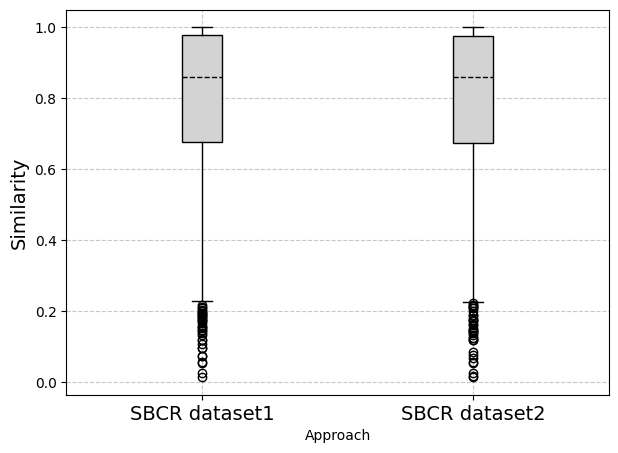

In [8]:
plt.figure(figsize=(7, 5)) 
plt.boxplot([df_sbcr_clean['sim_sbcr_ds1'], df_sbcr_clean['sim_sbcr_ds2']], 
            patch_artist=True, 
#             widths=0.5,  # Width of the box
            medianprops=dict(color='black', linestyle='--'),  
            boxprops=dict(facecolor='lightgray', color='black'),  
            whiskerprops=dict(color='black'),
            capprops=dict(color='black'),  
            showfliers=True)

plt.xlabel('Approach')
plt.ylabel('Similarity', fontsize=14)
plt.xticks([1, 2], ['SBCR dataset1', 'SBCR dataset2'], fontsize=14)

plt.grid(True, linestyle='--', alpha=0.7)
plt.savefig('RQ3_SBCR_similarity_dataset2.png', dpi=300) 
plt.show()  

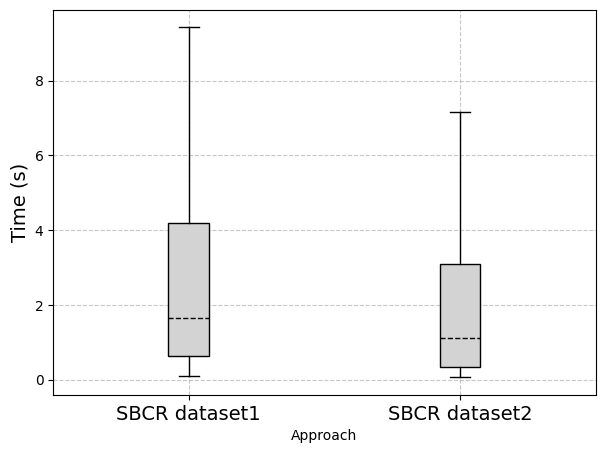

In [9]:
plt.figure(figsize=(7, 5)) 
plt.boxplot([df_sbcr_clean['time_sbcr_ds1'], df_sbcr_clean['time_sbcr_ds2']], 
            patch_artist=True, 
#             widths=0.5,  # Width of the box
            medianprops=dict(color='black', linestyle='--'),  
            boxprops=dict(facecolor='lightgray', color='black'),  
            whiskerprops=dict(color='black'),
            capprops=dict(color='black'),  
            showfliers=False)

plt.xlabel('Approach')
plt.ylabel('Time (s)', fontsize=14)
plt.xticks([1, 2], ['SBCR dataset1', 'SBCR dataset2'], fontsize=14)
plt.grid(True, linestyle='--', alpha=0.7)
plt.savefig('RQ3_SBCR_time_dataset2.png', dpi=300) 
plt.show()  

In [10]:
# Normality test
stat_shapiro_ds1, p_shapiro_ds1 = stats.shapiro(df_sbcr_clean['sim_sbcr_ds1'])
stat_shapiro_ds2, p_shapiro_ds2 = stats.shapiro(df_sbcr_clean['sim_sbcr_ds2'])

print(f"Shapiro-Wilk Test for dataset1: W={stat_shapiro_ds1}, p={p_shapiro_ds1}")
print(f"Shapiro-Wilk Test for dataset2: W={stat_shapiro_ds2}, p={p_shapiro_ds2}")

# Homocedasticity test
stat_levene, p_levene = stats.levene(df_sbcr_clean['sim_sbcr_ds1'], df_sbcr_clean['sim_sbcr_ds2'])

print(f"Levene Test: W={stat_levene}, p={p_levene}")

Shapiro-Wilk Test for dataset1: W=0.8704761266708374, p=1.3678661734590784e-37
Shapiro-Wilk Test for dataset2: W=0.8739269971847534, p=3.2943295995705386e-37
Levene Test: W=0.10747037152160634, p=0.7430601217798143


In [11]:
# Not normal and not homocedastic. We use non-parametric paired test Wilcoxon
pg.wilcoxon(df_sbcr_clean['sim_sbcr_ds1'], df_sbcr_clean['sim_sbcr_ds2'], alternative='two-sided')

# https://pingouin-stats.org/build/html/index.html
# Interpretation: https://peterstatistics.com/Terms/Correlations/RankBiserialCorrelation.html

,W-val,alternative,p-val,RBC,CLES
Wilcoxon,129754.0,two-sided,0.230523,0.050916,0.506127


### MergeGen trained on Dataset1 vs MergeGen trained on Dataset2_Java

In [12]:
df_complete = pd.read_json(DATASET2_COMPLETE)

In [13]:
df_mergegen_ds1 = pd.read_csv(MERGEGEN_DATASET1)
data = []
for index, row in df_mergegen_ds1.iterrows():
    chunk = df_complete.iloc[row['chunk_index']]
    chunk_id = f"{chunk['merge_id']}-{chunk['chunk_number']}"
    data.append(chunk_id)
df_mergegen_ds1['chunk_id'] = data
df_mergegen_ds1 = df_mergegen_ds1.rename(columns={"complete_similarity": "sim_mergegen", "time": "time_mergegen", "similarity":"sim_mergegen_trunc", "parents_similarity":"mergegen_parents_sim"})
df_mergegen_ds1.sort_values('chunk_id')

,chunk_index,sim_mergegen_trunc,sim_mergegen,time_mergegen,v1_similarity,v2_similarity,mergegen_parents_sim,result,chunk_id
4829,34189,1.000000,1.000000,0.115168,1.000000,0.885906,0.942953,SUCCEED,100004-3
177,8621,0.000000,0.000000,0.415754,0.000000,0.256410,0.128205,FAIL,100013-1
1587,8622,0.825397,0.830508,0.153938,0.830508,0.000000,0.415254,FAIL,100013-2
3547,9605,1.000000,1.000000,0.293847,0.000000,1.000000,0.500000,SUCCEED,100084-1
2350,58390,0.636364,0.642857,0.115627,0.000000,0.642857,0.321429,FAIL,100103-2
...,...,...,...,...,...,...,...,...,...
2286,63285,0.862745,0.862745,0.057039,1.000000,0.862745,0.931373,FAIL,99969-148
2346,63177,0.862745,0.862745,0.057800,1.000000,0.862745,0.931373,FAIL,99969-22
3921,63191,1.000000,1.000000,0.382698,0.837416,0.985263,0.911340,SUCCEED,99969-52
7,63201,0.862745,0.862745,0.057588,1.000000,0.862745,0.931373,FAIL,99969-62


In [14]:
df_mergegen_ds2 = pd.read_csv(MERGEGEN_DATASET2)
data = []
for index, row in df_mergegen_ds2.iterrows():
    chunk = df_complete.iloc[row['chunk_index']]
    chunk_id = f"{chunk['merge_id']}-{chunk['chunk_number']}"
    data.append(chunk_id)
df_mergegen_ds2['chunk_id'] = data
df_mergegen_ds2 = df_mergegen_ds2.rename(columns={"complete_similarity": "sim_mergegen", "time": "time_mergegen", "similarity":"sim_mergegen_trunc", "parents_similarity":"mergegen_parents_sim"})
df_mergegen_ds2.sort_values('chunk_id')

,chunk_index,sim_mergegen_trunc,sim_mergegen,time_mergegen,v1_similarity,v2_similarity,mergegen_parents_sim,result,chunk_id
4170,34189,1.000000,1.000000,0.118333,1.000000,0.885906,0.942953,SUCCEED,100004-3
2321,8621,1.000000,1.000000,0.389742,1.000000,0.000000,0.500000,SUCCEED,100013-1
4262,8622,1.000000,1.000000,0.160315,1.000000,0.000000,0.500000,SUCCEED,100013-2
2442,9605,1.000000,1.000000,0.311668,0.000000,1.000000,0.500000,SUCCEED,100084-1
1509,58390,0.636364,0.642857,0.113700,0.000000,0.642857,0.321429,FAIL,100103-2
...,...,...,...,...,...,...,...,...,...
5221,63285,1.000000,1.000000,0.072279,0.862745,1.000000,0.931373,SUCCEED,99969-148
5283,63177,1.000000,1.000000,0.073499,0.862745,1.000000,0.931373,SUCCEED,99969-22
2932,63191,1.000000,1.000000,0.397662,0.837416,0.985263,0.911340,SUCCEED,99969-52
2102,63201,1.000000,1.000000,0.073540,0.862745,1.000000,0.931373,SUCCEED,99969-62


In [15]:
df_mergegen = df_mergegen_ds1.merge(df_mergegen_ds2, on='chunk_id', suffixes=('_ds1', '_ds2'))
df_mergegen

,chunk_index_ds1,sim_mergegen_trunc_ds1,sim_mergegen_ds1,time_mergegen_ds1,v1_similarity_ds1,v2_similarity_ds1,mergegen_parents_sim_ds1,result_ds1,chunk_id,chunk_index_ds2,sim_mergegen_trunc_ds2,sim_mergegen_ds2,time_mergegen_ds2,v1_similarity_ds2,v2_similarity_ds2,mergegen_parents_sim_ds2,result_ds2
0,59484,0.000000,0.000000,1.289259,0.356476,0.755187,0.555831,FAIL,228576-22,59484,0.000000,0.000000,1.323704,0.242101,0.810920,0.526510,FAIL
1,1491,0.980392,0.958333,0.064080,0.958333,1.000000,0.979167,FAIL,214661-2,1491,0.980392,0.958333,0.065673,0.958333,1.000000,0.979167,FAIL
2,27472,0.000000,0.000000,0.652215,0.146982,0.000000,0.073491,FAIL,190323-10,27472,0.000000,0.000000,0.624698,0.910688,0.000000,0.455344,FAIL
3,44031,0.639344,0.620690,0.131144,0.696629,0.635294,0.665962,FAIL,267141-1,44031,0.639344,0.620690,0.132782,0.696629,0.635294,0.665962,FAIL
4,36386,0.684685,0.693878,0.070638,0.500000,1.000000,0.750000,FAIL,267569-7,36386,1.000000,1.000000,0.126571,0.638298,0.693878,0.666088,SUCCEED
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6570,20687,1.000000,1.000000,0.178132,0.416938,1.000000,0.708469,SUCCEED,247986-2,20687,1.000000,1.000000,0.185633,0.416938,1.000000,0.708469,SUCCEED
6571,36418,1.000000,1.000000,0.395311,0.880000,0.349776,0.614888,SUCCEED,167007-1,36418,0.775120,0.783383,0.414093,0.877076,0.455357,0.666217,FAIL
6572,17318,0.634731,0.588179,1.299691,0.589303,0.477345,0.533324,SUCCEED,251982-2,17318,0.642424,0.574427,1.345178,0.572658,0.370607,0.471632,SUCCEED
6573,45321,1.000000,1.000000,0.235969,1.000000,0.691667,0.845833,SUCCEED,192296-2,45321,1.000000,1.000000,0.242553,1.000000,0.691667,0.845833,SUCCEED


In [16]:
# we need to filter with sbcr to eliminate chunks that are not resolved with combination
df_mergegen = df_mergegen[df_mergegen['chunk_id'].isin(list(df_sbcr_clean['chunk_id'].unique()))]

In [17]:
df_mergegen_clean = df_mergegen.dropna(subset=['sim_mergegen_ds1', 'sim_mergegen_ds2'])
df_mergegen_clean

,chunk_index_ds1,sim_mergegen_trunc_ds1,sim_mergegen_ds1,time_mergegen_ds1,v1_similarity_ds1,v2_similarity_ds1,mergegen_parents_sim_ds1,result_ds1,chunk_id,chunk_index_ds2,sim_mergegen_trunc_ds2,sim_mergegen_ds2,time_mergegen_ds2,v1_similarity_ds2,v2_similarity_ds2,mergegen_parents_sim_ds2,result_ds2
19,41460,0.836066,0.815126,0.242139,0.877828,0.692308,0.785068,FAIL,151906-1,41460,0.836066,0.815126,0.248137,0.877828,0.692308,0.785068,FAIL
43,16927,0.791045,0.793651,0.193140,0.432990,0.839695,0.636342,FAIL,118040-2,16927,0.597015,0.587302,0.197680,0.432990,0.839695,0.636342,FAIL
45,60560,0.490446,0.486301,0.494572,0.436620,0.529851,0.483235,FAIL,78151-3,60560,1.000000,1.000000,0.652641,0.963134,0.942584,0.952859,SUCCEED
46,5966,0.768116,0.769231,0.163135,0.901235,0.490566,0.695900,FAIL,82730-1,5966,0.675000,0.684211,0.215034,0.444444,1.000000,0.722222,FAIL
59,31559,0.675497,0.680272,0.185888,0.660194,0.680628,0.670411,FAIL,75221-1,31559,0.675497,0.680272,0.190332,0.941748,0.848168,0.894958,FAIL
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6557,58686,1.000000,1.000000,0.363745,0.961098,0.733333,0.847216,SUCCEED,99584-2,58686,1.000000,1.000000,0.373008,0.961098,0.733333,0.847216,SUCCEED
6559,31764,1.000000,1.000000,0.249657,0.607143,0.923077,0.765110,SUCCEED,240777-8,31764,1.000000,1.000000,0.256069,0.607143,0.923077,0.765110,SUCCEED
6564,54677,1.000000,1.000000,0.103410,0.931034,0.735294,0.833164,SUCCEED,50343-5,54677,1.000000,1.000000,0.093899,0.931034,0.735294,0.833164,SUCCEED
6571,36418,1.000000,1.000000,0.395311,0.880000,0.349776,0.614888,SUCCEED,167007-1,36418,0.775120,0.783383,0.414093,0.877076,0.455357,0.666217,FAIL


In [18]:
print(df_mergegen_clean[['sim_mergegen_ds1', 'sim_mergegen_ds2', 'time_mergegen_ds1', 'time_mergegen_ds2']].describe())

       sim_mergegen_ds1  sim_mergegen_ds2  time_mergegen_ds1  \
count       1967.000000       1967.000000        1967.000000   
mean           0.893612          0.893023           0.446660   
std            0.190329          0.204414           0.373684   
min            0.049669          0.000000           0.032257   
25%            0.858233          0.866018           0.185208   
50%            1.000000          1.000000           0.302055   
75%            1.000000          1.000000           0.556587   
max            1.000000          1.000000           1.324865   

       time_mergegen_ds2  
count        1967.000000  
mean            0.492146  
std             0.398674  
min             0.039297  
25%             0.215865  
50%             0.335696  
75%             0.599878  
max             1.402251  


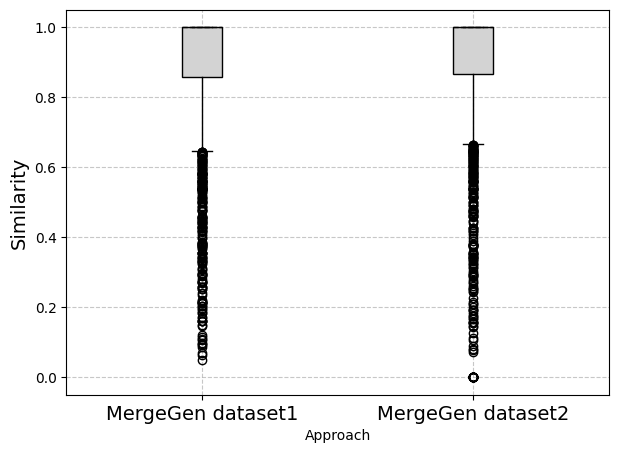

In [19]:
plt.figure(figsize=(7, 5)) 
plt.boxplot([df_mergegen_clean['sim_mergegen_ds1'], df_mergegen_clean['sim_mergegen_ds2']], 
            patch_artist=True, 
#             widths=0.5,  # Width of the box
            medianprops=dict(color='black', linestyle='--'),  
            boxprops=dict(facecolor='lightgray', color='black'),  
            whiskerprops=dict(color='black'),
            capprops=dict(color='black'),  
            showfliers=True)
# plt.title("Comparing MergeGen's output (truncated) \n to the complete ground truth")
plt.xlabel('Approach')
plt.ylabel('Similarity', fontsize=14)
plt.xticks([1, 2], ['MergeGen dataset1', 'MergeGen dataset2'], fontsize=14)
plt.grid(True, linestyle='--', alpha=0.7)
plt.savefig('RQ3_MergeGen_similarity_dataset2.png', dpi=300) 
plt.show()  

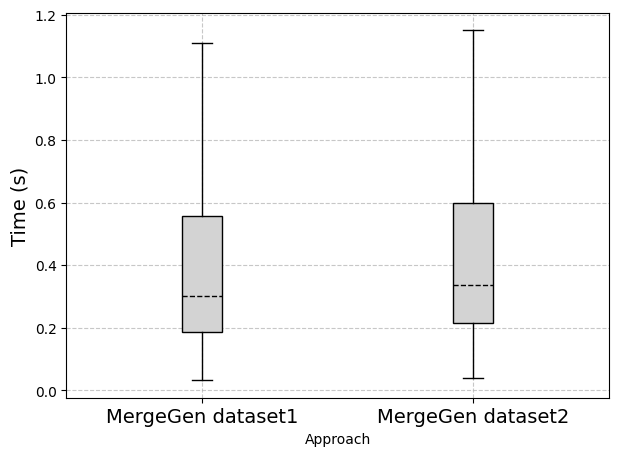

In [20]:
plt.figure(figsize=(7, 5)) 
plt.boxplot([df_mergegen_clean['time_mergegen_ds1'], df_mergegen_clean['time_mergegen_ds2']], 
            patch_artist=True, 
#             widths=0.5,  # Width of the box
            medianprops=dict(color='black', linestyle='--'),  
            boxprops=dict(facecolor='lightgray', color='black'),  
            whiskerprops=dict(color='black'),
            capprops=dict(color='black'),  
            showfliers=False)
plt.xlabel('Approach')
plt.ylabel('Time (s)', fontsize=14)
plt.xticks([1, 2], ['MergeGen dataset1', 'MergeGen dataset2'], fontsize=14)
plt.grid(True, linestyle='--', alpha=0.7)
plt.savefig('RQ3_MergeGen_time_dataset2.png', dpi=300) 
plt.show()  

In [35]:
for i in range(200, len(df_mergegen_clean['sim_mergegen_ds1']), 200):
    stat, p_value = stats.shapiro(df_mergegen_clean['sim_mergegen_ds1'][:i])
    print(stat, p_value)

0.936260461807251 1.0971517383495666e-07
0.9298883676528931 9.364521961693906e-13
0.9226299524307251 5.335245798667819e-17
0.8616596460342407 6.162602962001921e-26
0.8007194995880127 2.5379101195115734e-33
0.7513185143470764 4.377795131098697e-39
0.7134566307067871 1.064986832886861e-43
0.6812014579772949 0.0
0.6542236804962158 0.0


In [36]:
for i in range(200, len(df_mergegen_clean['sim_mergegen_ds2']), 200):
    stat, p_value = stats.shapiro(df_mergegen_clean['sim_mergegen_ds2'][:i])
    print(stat, p_value)

0.8752472996711731 8.650211623384418e-12
0.8530722260475159 6.596344556973759e-19
0.8320574760437012 1.2784609179439647e-24
0.7723166942596436 7.265477851147132e-32
0.7185623645782471 5.916804520446878e-38
0.678136944770813 7.763193492359487e-43
0.6507824659347534 0.0
0.6310348510742188 0.0
0.6129794120788574 0.0


In [31]:
# Normality test
stat_shapiro_ds1, p_shapiro_ds1 = stats.shapiro(df_mergegen_clean['sim_mergegen_ds1'])
stat_shapiro_ds2, p_shapiro_ds2 = stats.shapiro(df_mergegen_clean['sim_mergegen_ds2'])

print(f"Shapiro-Wilk Test for dataset1: W={stat_shapiro_ds1}, p={p_shapiro_ds1}")
print(f"Shapiro-Wilk Test for dataset2: W={stat_shapiro_ds2}, p={p_shapiro_ds2}")

# Homocedasticity test
stat_levene, p_levene = stats.levene(df_mergegen_clean['sim_mergegen_ds1'], df_mergegen_clean['sim_mergegen_ds2'])

print(f"Levene Test: W={stat_levene}, p={p_levene}")

Shapiro-Wilk Test for dataset1: W=0.632075309753418, p=0.0
Shapiro-Wilk Test for dataset2: W=0.5960827469825745, p=0.0
Levene Test: W=0.008760696429101381, p=0.9254327968928909


In [22]:
# Not normal and not homocedastic. We use non-parametric paired test Wilcoxon
pg.wilcoxon(df_mergegen_clean['sim_mergegen_ds1'], df_mergegen_clean['sim_mergegen_ds2'], alternative='two-sided')

# https://pingouin-stats.org/build/html/index.html
# Interpretation: https://peterstatistics.com/Terms/Correlations/RankBiserialCorrelation.html

,W-val,alternative,p-val,RBC,CLES
Wilcoxon,97148.5,two-sided,0.021021,-0.103842,0.490111


### SBCR trained on Dataset1 vs MergeGen trained on Dataset1


In [23]:
df_both = df_sbcr_clean.merge(df_mergegen_clean, on='chunk_id')
df_both

,chunk_id,fitness_sbcr_ds1,sim_sbcr_ds1,status_ds1,time_sbcr_ds1,fitness_sbcr_ds2,sim_sbcr_ds2,status_ds2,time_sbcr_ds2,chunk_index_ds1,...,mergegen_parents_sim_ds1,result_ds1,chunk_index_ds2,sim_mergegen_trunc_ds2,sim_mergegen_ds2,time_mergegen_ds2,v1_similarity_ds2,v2_similarity_ds2,mergegen_parents_sim_ds2,result_ds2
0,247633-11,0.772002,0.413502,ok,0.243860,0.772002,0.413502,ok,0.195323,37554,...,0.589247,SUCCEED,37554,1.000000,1.000000,0.098506,0.645161,0.533333,0.589247,SUCCEED
1,218430-3,0.947421,1.000000,ok,1.524886,0.947421,1.000000,ok,0.825038,59863,...,0.939097,SUCCEED,59863,1.000000,1.000000,0.190504,0.951724,0.926471,0.939097,SUCCEED
2,64045-1,0.979891,0.981432,ok,0.996221,0.979891,0.981432,ok,2.291695,5235,...,0.979356,SUCCEED,5235,1.000000,1.000000,0.299400,0.980519,0.978193,0.979356,SUCCEED
3,276497-1,0.841141,0.947891,ok,2.646000,0.844135,1.000000,ok,0.300525,28978,...,0.838726,SUCCEED,28978,1.000000,0.984456,0.360160,0.709030,0.968421,0.838726,SUCCEED
4,228270-4,0.744453,0.822816,ok,0.810900,0.741226,0.818408,ok,0.874901,19428,...,0.723848,SUCCEED,19428,0.891473,1.000000,1.350036,0.607460,0.840237,0.723848,SUCCEED
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1962,258478-4,0.978499,0.980562,ok,2.600460,0.978495,1.000000,ok,1.557349,35832,...,0.977431,SUCCEED,35832,1.000000,1.000000,0.380552,0.976253,0.978610,0.977431,SUCCEED
1963,167370-1,0.676818,0.500189,ok,9.943668,0.688285,0.506004,ok,10.421561,17374,...,0.615597,FAIL,17374,0.666105,0.711382,1.345684,0.488923,0.719258,0.604090,FAIL
1964,91740-2,0.795016,0.793651,ok,4.012038,0.795016,0.793651,ok,2.451555,55023,...,0.788434,FAIL,55023,0.692308,0.696629,0.246882,0.645833,0.931034,0.788434,FAIL
1965,136898-33,0.968318,0.955372,ok,0.580410,0.968289,0.991394,ok,0.611825,39157,...,0.982399,SUCCEED,39157,1.000000,1.000000,0.545362,0.990050,0.974747,0.982399,SUCCEED


In [24]:
print(df_both[['sim_sbcr_ds1', 'sim_mergegen_ds1', 'time_sbcr_ds1', 'time_mergegen_ds1']].describe())

       sim_sbcr_ds1  sim_mergegen_ds1  time_sbcr_ds1  time_mergegen_ds1
count   1967.000000       1967.000000    1967.000000        1967.000000
mean       0.799322          0.893612       3.611963           0.446660
std        0.206089          0.190329       5.318878           0.373684
min        0.013220          0.049669       0.091140           0.032257
25%        0.676946          0.858233       0.637986           0.185208
50%        0.859729          1.000000       1.655087           0.302055
75%        0.977228          1.000000       4.186892           0.556587
max        1.000000          1.000000      69.450531           1.324865


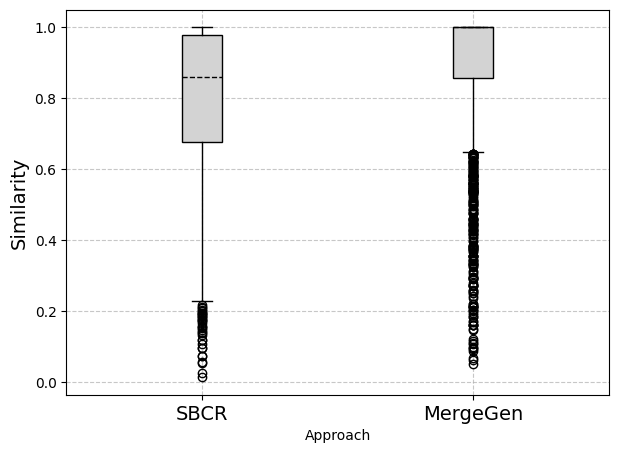

In [25]:
plt.figure(figsize=(7, 5)) 
plt.boxplot([df_both['sim_sbcr_ds1'], df_both['sim_mergegen_ds1']], 
            patch_artist=True, 
#             widths=0.5,  # Width of the box
            medianprops=dict(color='black', linestyle='--'),  
            boxprops=dict(facecolor='lightgray', color='black'),  
            whiskerprops=dict(color='black'),
            capprops=dict(color='black'),  
            showfliers=True)

plt.xlabel('Approach')
plt.ylabel('Similarity', fontsize=14)
plt.xticks([1, 2], ['SBCR', 'MergeGen'], fontsize=14)
plt.grid(True, linestyle='--', alpha=0.7)
plt.savefig('RQ3_versus_similarity_dataset2.png', dpi=300) 
plt.show()  

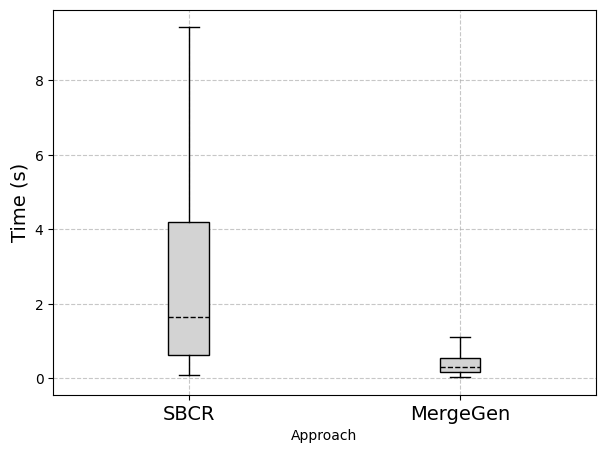

In [26]:
plt.figure(figsize=(7, 5)) 
plt.boxplot([df_both['time_sbcr_ds1'], df_both['time_mergegen_ds1']], 
            patch_artist=True, 
#             widths=0.5,  # Width of the box
            medianprops=dict(color='black', linestyle='--'),  
            boxprops=dict(facecolor='lightgray', color='black'),  
            whiskerprops=dict(color='black'),
            capprops=dict(color='black'),  
            showfliers=False)
plt.xlabel('Approach')
plt.ylabel('Time (s)', fontsize=14)
plt.xticks([1, 2], ['SBCR', 'MergeGen'], fontsize=14)

plt.grid(True, linestyle='--', alpha=0.7)
plt.savefig('RQ3_versus_time_dataset2.png', dpi=300) 
plt.show()  

In [27]:
print(len(df_both['sim_mergegen_ds1']))
print(len(df_both['sim_sbcr_ds1']))

1967
1967


In [28]:
for i in range(200, len(df_both['sim_mergegen_ds1']), 200):
    stat, p_value = stats.shapiro(df_both['sim_mergegen_ds1'][:i])
    print(stat, p_value)

0.5808084607124329 9.017532873760273e-22
0.6087828874588013 4.2688309439716e-29
0.6389966011047363 1.2385086540435355e-33
0.6360772252082825 4.920855739261601e-38
0.6275148391723633 6.007366516560491e-42
0.6214299201965332 2.802596928649634e-45
0.6298913955688477 0.0
0.6305235624313354 0.0
0.6303077936172485 0.0


In [29]:
# Normality test
stat_shapiro_sbcr, p_shapiro_sbcr = stats.shapiro(df_both['sim_sbcr_ds1'])
stat_shapiro_mergegen, p_shapiro_mergegen = stats.shapiro(df_both['sim_mergegen_ds1'])

print(f"Shapiro-Wilk Test for sbcr: W={stat_shapiro_sbcr}, p={p_shapiro_sbcr}")
print(f"Shapiro-Wilk Test for mergegen: W={stat_shapiro_mergegen}, p={p_shapiro_mergegen}")

# Homocedasticity test
stat_levene, p_levene = stats.levene(df_both['sim_sbcr_ds1'], df_both['sim_mergegen_ds1'])

print(f"Levene Test: W={stat_levene}, p={p_levene}")

Shapiro-Wilk Test for sbcr: W=0.8704761266708374, p=1.3678661734590784e-37
Shapiro-Wilk Test for mergegen: W=0.632075309753418, p=0.0
Levene Test: W=107.64022014856344, p=6.734136956394628e-25


In [30]:
# Not normal and not homocedastic. We use non-parametric paired test Wilcoxon
pg.wilcoxon(df_both['sim_sbcr_ds1'], df_both['sim_mergegen_ds1'], alternative='two-sided')

# https://pingouin-stats.org/build/html/index.html
# Interpretation: https://peterstatistics.com/Terms/Correlations/RankBiserialCorrelation.html

,W-val,alternative,p-val,RBC,CLES
Wilcoxon,338692.5,two-sided,2.448586e-80,-0.531497,0.308087
